# Drift-RAG — Results Figures & Tables

Generates all manuscript-ready figures and tables from `results/tables/*.json`.

**Run this notebook from the `drift-rag/` repo root** (i.e. one level above `results/`),
or adjust `RESULTS_DIR` in the config cell below.

Every figure is saved twice: a `.png` (300 DPI, for quick preview / Word) and a
`.pdf` (vector, for LaTeX) into `results/figures_final/`.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# --------------------------- CONFIG -----------------------------------------
RESULTS_DIR = Path("results")
TABLES_DIR = RESULTS_DIR / "tables"
FIG_OUT_DIR = RESULTS_DIR / "figures_final"
FIG_OUT_DIR.mkdir(parents=True, exist_ok=True)

# Number of leading samples to drop from timing_breakdown.json's "encode" array.
# These look like cold-start / model-load outliers (thousands of ms vs a steady
# ~50-450 ms afterward). Adjust this if you know the exact warm-up count from
# your benchmarking script; inspect the printed diagnostic in the timing cell
# below before trusting the trimmed stats.
ENCODE_WARMUP_TRIM = 2

# Consistent condition -> color/label mapping used across EVERY figure.
CONDITION_STYLE = {
    "oracle":         {"color": "#000000", "label": "Oracle (re-embedded)"},
    "naive":          {"color": "#999999", "label": "Naive (no compensation)"},
    "l0_compensated": {"color": "#4C72B0", "label": "L0 (translation)"},
    "l1_compensated": {"color": "#C44E52", "label": "L1 (rotation)"},
    "l2_compensated": {"color": "#55A868", "label": "L2 (rotation + cluster bias)"},
}
CONDITION_ORDER = ["oracle", "l1_compensated", "l2_compensated", "l0_compensated", "naive"]

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 11,
    "font.family": "serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "grid.linewidth": 0.6,
})

def load_json(name):
    path = TABLES_DIR / name
    if not path.exists():
        raise FileNotFoundError(
            f"Could not find {path}. Run this notebook from the drift-rag repo root, "
            f"or update RESULTS_DIR above."
        )
    with open(path) as f:
        return json.load(f)

def save_fig(fig, name):
    fig.savefig(FIG_OUT_DIR / f"{name}.png", bbox_inches="tight")
    fig.savefig(FIG_OUT_DIR / f"{name}.pdf", bbox_inches="tight")
    print(f"Saved {name}.png / {name}.pdf -> {FIG_OUT_DIR}/")


## 1. Adapter Evaluation (NDCG@10 / Recall@10 by condition)

Loads `adapter_evaluation.json`. **Note:** if an epoch is missing one or more
conditions (e.g. only `oracle` present), this is flagged explicitly rather than
silently plotted as zero — check the printed warning before trusting that
epoch's figures.


In [2]:
adapter_raw = load_json("adapter_evaluation.json")
df_adapter = pd.DataFrame(adapter_raw["results"])

# --- Completeness check: every epoch should have all 5 conditions ----------
expected_conditions = set(CONDITION_STYLE.keys())
for epoch, group in df_adapter.groupby("epoch"):
    present = set(group["condition"])
    missing = expected_conditions - present
    if missing:
        print(f"[WARNING] epoch {epoch} is missing conditions: {sorted(missing)} "
              f"-- figures for this epoch will only show what's present.")

df_adapter


[WARNING] epoch 3 is missing conditions: ['l0_compensated', 'l1_compensated', 'l2_compensated', 'naive'] -- figures for this epoch will only show what's present.


,epoch,condition,ndcg_at_10,recall_at_10,n_queries
0,1,oracle,0.791010,0.844,500
1,1,naive,0.000000,0.000,500
2,1,l1_compensated,0.772232,0.834,500
3,1,l0_compensated,0.000667,0.002,500
4,1,l2_compensated,0.770502,0.834,500
5,2,oracle,0.866164,0.910,500
6,2,naive,0.000712,0.002,500
7,2,l1_compensated,0.809519,0.884,500
8,2,l0_compensated,0.000000,0.000,500
9,2,l2_compensated,0.798784,0.876,500


In [4]:
# --- Recovery ratio: how much of oracle NDCG@10 does each condition recover? ---
oracle_ndcg = df_adapter[df_adapter.condition == "oracle"].set_index("epoch")["ndcg_at_10"]

df_adapter = df_adapter.copy()
df_adapter["oracle_ndcg_at_10"] = df_adapter["epoch"].map(oracle_ndcg)
df_adapter["recovery_pct"] = (df_adapter["ndcg_at_10"] / df_adapter["oracle_ndcg_at_10"] * 100).round(1)
df_adapter.loc[df_adapter.condition == "oracle", "recovery_pct"] = 100.0

table_adapter = (
    df_adapter
    .pivot_table(index="epoch", columns="condition", values=["ndcg_at_10", "recall_at_10", "recovery_pct"])
    .round(4)
)
table_adapter.to_csv(TABLES_DIR.parent / "tables_formatted" / "adapter_evaluation_table.csv") \
    if (TABLES_DIR.parent / "tables_formatted").exists() else None
Path_ = TABLES_DIR.parent / "tables_formatted"
Path_.mkdir(exist_ok=True)
table_adapter.to_csv(Path_ / "adapter_evaluation_table.csv")
table_adapter.to_markdown(Path_ / "adapter_evaluation_table.md")
print(f"Saved formatted table -> {Path_}/adapter_evaluation_table.{{csv,md}}")
table_adapter


Saved formatted table -> results/tables_formatted/adapter_evaluation_table.{csv,md}


ndcg_at_10                                                \
condition l0_compensated l1_compensated l2_compensated   naive  oracle   
epoch                                                                    
1                 0.0007         0.7722         0.7705  0.0000  0.7910   
2                 0.0000         0.8095         0.7988  0.0007  0.8662   
3                    NaN            NaN            NaN     NaN  0.8951   

            recall_at_10                                              \
condition l0_compensated l1_compensated l2_compensated  naive oracle   
epoch                                                                  
1                  0.002          0.834          0.834  0.000  0.844   
2                  0.000          0.884          0.876  0.002  0.910   
3                    NaN            NaN            NaN    NaN  0.940   

            recovery_pct                                             
condition l0_compensated l1_compensated l2_compensated naive oracle  
epoch                                                                
1                    0.1           97.6           97.4   0.0  100.0  
2                    0.0           93.5           92.2   0.1  100.0  
3                    NaN            NaN            NaN   NaN  100.0

Saved ndcg_by_condition.png / ndcg_by_condition.pdf -> results/figures_final/


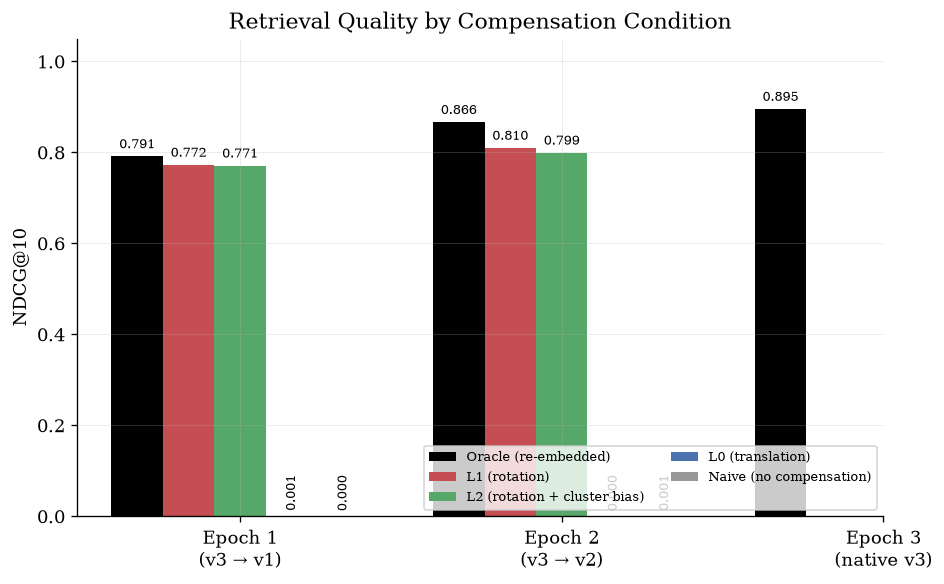

In [5]:
# --- Figure: NDCG@10 by condition, grouped by epoch, with value annotations ---
epochs = sorted(df_adapter["epoch"].unique())
conditions_present = [c for c in CONDITION_ORDER if c in df_adapter["condition"].unique()]

fig, ax = plt.subplots(figsize=(8, 5))
n_cond = len(conditions_present)
bar_width = 0.8 / n_cond
x = np.arange(len(epochs))

for i, cond in enumerate(conditions_present):
    vals = []
    for e in epochs:
        row = df_adapter[(df_adapter.epoch == e) & (df_adapter.condition == cond)]
        vals.append(row["ndcg_at_10"].values[0] if len(row) else np.nan)
    offset = (i - (n_cond - 1) / 2) * bar_width
    bars = ax.bar(x + offset, vals, width=bar_width,
                   color=CONDITION_STYLE[cond]["color"], label=CONDITION_STYLE[cond]["label"])
    for b, v in zip(bars, vals):
        if not np.isnan(v):
            ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width() / 2, v),
                        textcoords="offset points", xytext=(0, 3),
                        ha="center", fontsize=8, rotation=90 if v < 0.15 else 0,
                        va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([f"Epoch {e}\n(v3 \u2192 v{e})" if e != max(epochs) else f"Epoch {e}\n(native v3)"
                     for e in epochs])
ax.set_ylabel("NDCG@10")
ax.set_ylim(0, 1.05)
ax.set_title("Retrieval Quality by Compensation Condition")
ax.legend(loc="lower right", fontsize=8, ncol=2)
fig.tight_layout()
save_fig(fig, "ndcg_by_condition")
plt.show()


Saved recall_by_condition.png / recall_by_condition.pdf -> results/figures_final/


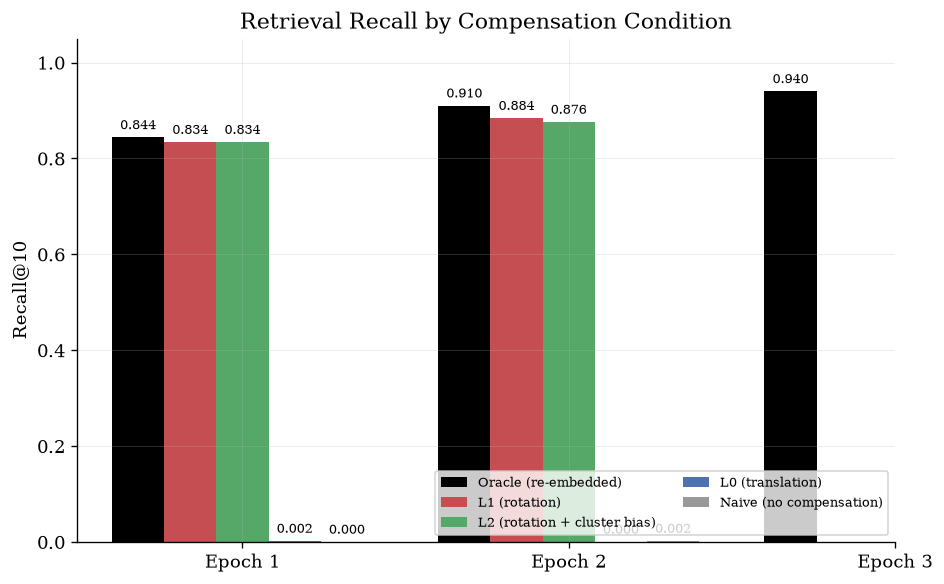

In [6]:
# --- Figure: Recall@10 by condition (same layout as above) --------------------
fig, ax = plt.subplots(figsize=(8, 5))
for i, cond in enumerate(conditions_present):
    vals = []
    for e in epochs:
        row = df_adapter[(df_adapter.epoch == e) & (df_adapter.condition == cond)]
        vals.append(row["recall_at_10"].values[0] if len(row) else np.nan)
    offset = (i - (n_cond - 1) / 2) * bar_width
    bars = ax.bar(x + offset, vals, width=bar_width,
                   color=CONDITION_STYLE[cond]["color"], label=CONDITION_STYLE[cond]["label"])
    for b, v in zip(bars, vals):
        if not np.isnan(v):
            ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width() / 2, v),
                        textcoords="offset points", xytext=(0, 3),
                        ha="center", fontsize=8, va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([f"Epoch {e}" for e in epochs])
ax.set_ylabel("Recall@10")
ax.set_ylim(0, 1.05)
ax.set_title("Retrieval Recall by Compensation Condition")
ax.legend(loc="lower right", fontsize=8, ncol=2)
fig.tight_layout()
save_fig(fig, "recall_by_condition")
plt.show()


Saved recovery_ratio_l0_l1_l2.png / recovery_ratio_l0_l1_l2.pdf -> results/figures_final/


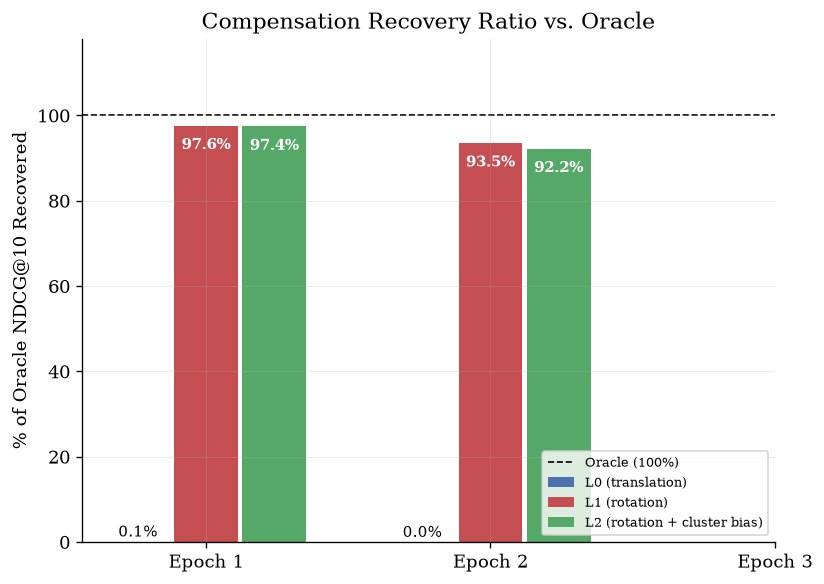

In [7]:
# --- Figure: Recovery ratio (% of oracle NDCG@10) for L0/L1/L2, per epoch -----
compensated = ["l0_compensated", "l1_compensated", "l2_compensated"]
fig, ax = plt.subplots(figsize=(7, 5))
for i, cond in enumerate(compensated):
    vals = []
    for e in epochs:
        row = df_adapter[(df_adapter.epoch == e) & (df_adapter.condition == cond)]
        vals.append(row["recovery_pct"].values[0] if len(row) else np.nan)
    offset = (i - 1) * bar_width * 1.5
    bars = ax.bar(x + offset, vals, width=bar_width * 1.4,
                   color=CONDITION_STYLE[cond]["color"], label=CONDITION_STYLE[cond]["label"])
    for b, v in zip(bars, vals):
        if not np.isnan(v):
            # Place the label just *inside* the bar (below its top) when the bar is
            # tall enough to collide with the y=100 oracle reference line; otherwise
            # keep it just above the bar as usual.
            if v > 90:
                ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, v),
                            textcoords="offset points", xytext=(0, -14), ha="center",
                            fontsize=9, color="white", fontweight="bold")
            else:
                ax.annotate(f"{v:.1f}%", (b.get_x() + b.get_width() / 2, v),
                            textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)

ax.axhline(100, color="black", linestyle="--", linewidth=1, label="Oracle (100%)", zorder=1)
ax.set_xticks(x)
ax.set_xticklabels([f"Epoch {e}" for e in epochs])
ax.set_ylabel("% of Oracle NDCG@10 Recovered")
ax.set_ylim(0, 118)
ax.set_title("Compensation Recovery Ratio vs. Oracle")
ax.legend(loc="lower right", fontsize=8)
fig.tight_layout()
save_fig(fig, "recovery_ratio_l0_l1_l2")
plt.show()


## 2. Cost Baseline (re-embedding vs. calibration-only cost)

In [8]:
cost_raw = load_json("cost_baseline.json")
df_cost = pd.DataFrame(cost_raw["results"])

table_cost = df_cost[["epoch", "model_key", "corpus_size", "calibration_size",
                       "full_reembed_hours", "calibration_only_minutes", "savings_ratio"]].round(2)
table_cost.to_csv(Path_ / "cost_baseline_table.csv", index=False)
table_cost.to_markdown(Path_ / "cost_baseline_table.md", index=False)
table_cost


,epoch,model_key,corpus_size,calibration_size,full_reembed_hours,calibration_only_minutes,savings_ratio
0,1,v1,88209,2333,6.82,10.83,37.81
1,2,v2,86577,2333,7.36,11.90,37.11
2,3,v3,85254,2333,9.26,15.20,36.54


Saved cost_comparison.png / cost_comparison.pdf -> results/figures_final/


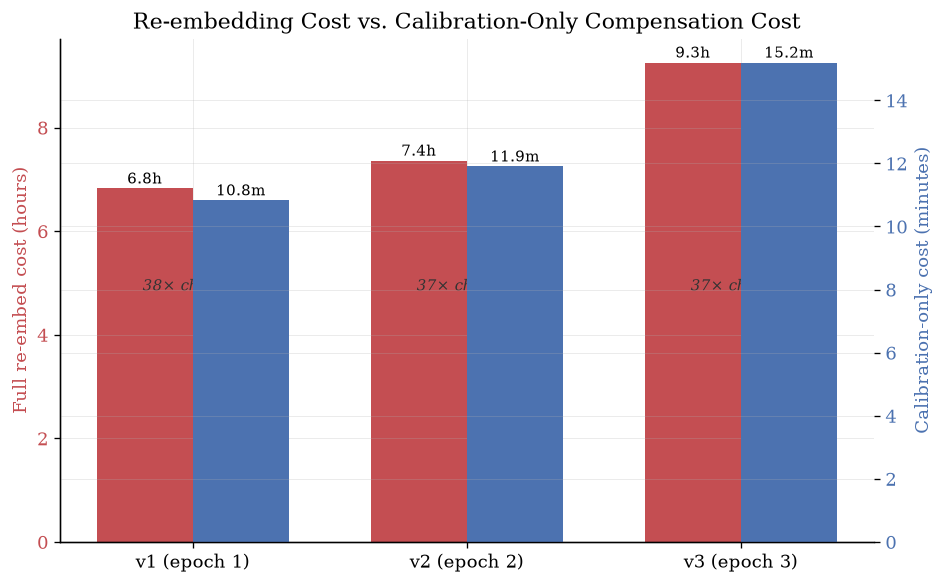

In [9]:
fig, ax1 = plt.subplots(figsize=(8, 5))
x = np.arange(len(df_cost))
width = 0.35

b1 = ax1.bar(x - width/2, df_cost["full_reembed_hours"], width,
             color="#C44E52", label="Full re-embed (hours)")
ax1.set_ylabel("Full re-embed cost (hours)", color="#C44E52")
ax1.tick_params(axis="y", labelcolor="#C44E52")
for b, v in zip(b1, df_cost["full_reembed_hours"]):
    ax1.annotate(f"{v:.1f}h", (b.get_x() + b.get_width()/2, v),
                 textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)

ax2 = ax1.twinx()
b2 = ax2.bar(x + width/2, df_cost["calibration_only_minutes"], width,
             color="#4C72B0", label="Calibration-only (minutes)")
ax2.set_ylabel("Calibration-only cost (minutes)", color="#4C72B0")
ax2.tick_params(axis="y", labelcolor="#4C72B0")
for b, v in zip(b2, df_cost["calibration_only_minutes"]):
    ax2.annotate(f"{v:.1f}m", (b.get_x() + b.get_width()/2, v),
                 textcoords="offset points", xytext=(0, 3), ha="center", fontsize=9)

for xi, ratio in zip(x, df_cost["savings_ratio"]):
    ax1.annotate(f"{ratio:.0f}\u00d7 cheaper", (xi, ax1.get_ylim()[1]*0.5),
                 ha="center", fontsize=9, style="italic", color="#333333")

ax1.set_xticks(x)
ax1.set_xticklabels([f"v{r.model_key[-1]} (epoch {r.epoch})" for r in df_cost.itertuples()])
ax1.set_title("Re-embedding Cost vs. Calibration-Only Compensation Cost")
fig.tight_layout()
save_fig(fig, "cost_comparison")
plt.show()


## 3. Drift Measurement (MMD\u00b2 before / after L1 compensation)

In [10]:
drift_raw = load_json("drift_measurement.json")
df_drift = pd.DataFrame(drift_raw["results"])
table_drift = df_drift.round(4)
table_drift.to_csv(Path_ / "drift_measurement_table.csv", index=False)
table_drift.to_markdown(Path_ / "drift_measurement_table.md", index=False)
table_drift


,target,mmd2_before,mmd2_after,reduction_pct
0,v1,0.3964,0.0689,82.6224
1,v2,0.2625,0.0029,98.8964


Saved recovery_ratio.png / recovery_ratio.pdf -> results/figures_final/


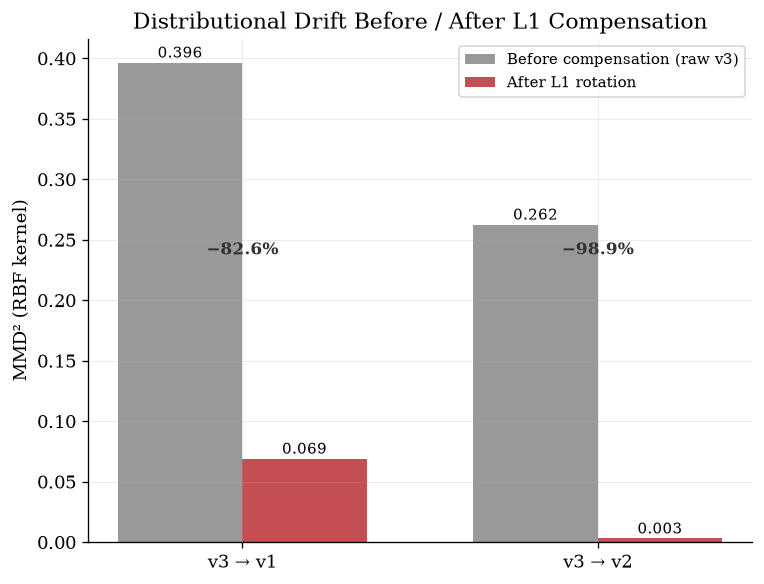

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))
x = np.arange(len(df_drift))
width = 0.35
b1 = ax.bar(x - width/2, df_drift["mmd2_before"], width, color="#999999", label="Before compensation (raw v3)")
b2 = ax.bar(x + width/2, df_drift["mmd2_after"], width, color="#C44E52", label="After L1 rotation")

for b, v in zip(b1, df_drift["mmd2_before"]):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width()/2, v), textcoords="offset points",
                xytext=(0, 3), ha="center", fontsize=9)
for b, v in zip(b2, df_drift["mmd2_after"]):
    ax.annotate(f"{v:.3f}", (b.get_x() + b.get_width()/2, v), textcoords="offset points",
                xytext=(0, 3), ha="center", fontsize=9)

for xi, red in zip(x, df_drift["reduction_pct"]):
    ax.annotate(f"\u2212{red:.1f}%", (xi, max(df_drift['mmd2_before']) * 0.6),
                ha="center", fontsize=10, fontweight="bold", color="#333333")

ax.set_xticks(x)
ax.set_xticklabels([f"v3 \u2192 {t}" for t in df_drift["target"]])
ax.set_ylabel("MMD\u00b2 (RBF kernel)")
ax.set_title("Distributional Drift Before / After L1 Compensation")
ax.legend(fontsize=9)
fig.tight_layout()
save_fig(fig, "recovery_ratio")  # kept filename consistent with existing results/figures/recovery_ratio.png
plt.show()


## 4. Index Comparison (Flat vs. IVF FAISS)

In [12]:
idx_raw = load_json("index_comparison.json")
df_idx = pd.DataFrame(idx_raw["results"])
table_idx = df_idx.round(4)
table_idx.to_csv(Path_ / "index_comparison_table.csv", index=False)
table_idx.to_markdown(Path_ / "index_comparison_table.md", index=False)
table_idx


,epoch,index_type,ndcg_at_10,recall_at_10,avg_query_latency_ms,n_queries
0,1,flat,0.7608,0.864,1.4336,500
1,1,ivf,0.6760,0.760,0.2305,500
2,2,flat,0.8003,0.896,1.4187,500
3,2,ivf,0.7324,0.820,0.1902,500
4,3,flat,0.8890,0.966,1.1740,500
5,3,ivf,0.8204,0.890,0.0898,500


Saved index_comparison.png / index_comparison.pdf -> results/figures_final/


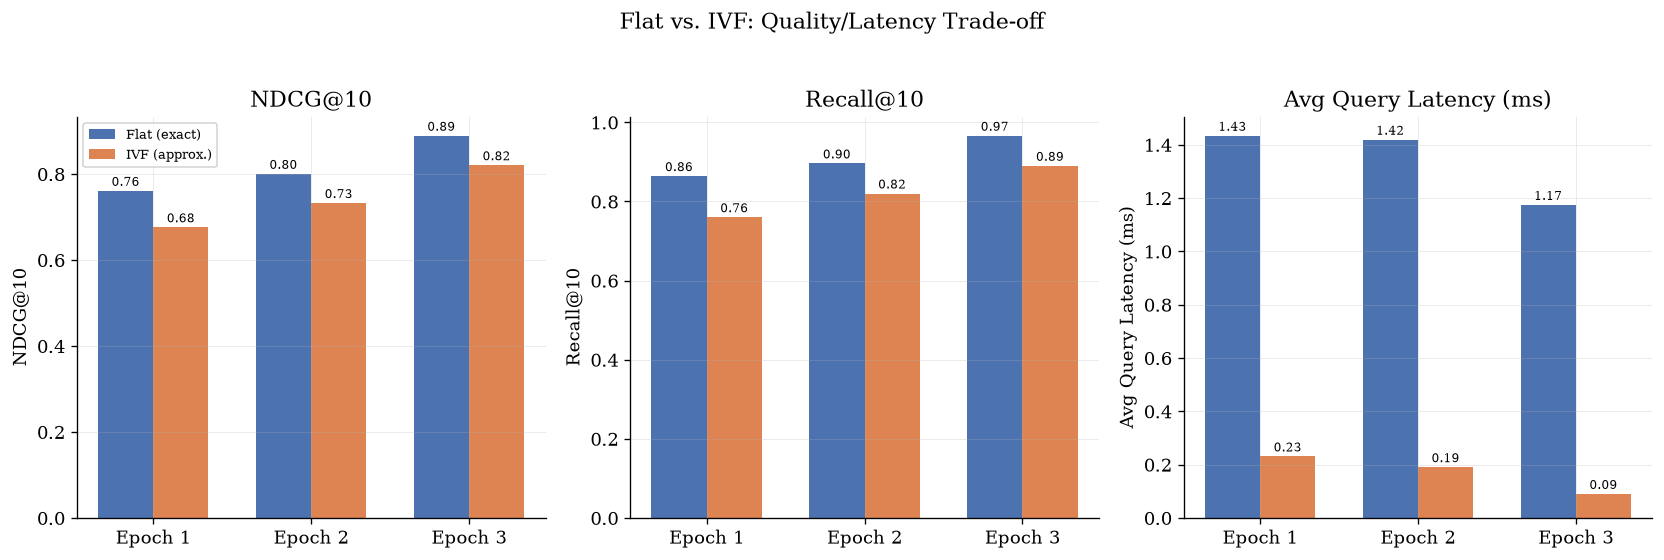

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
metrics = [("ndcg_at_10", "NDCG@10"), ("recall_at_10", "Recall@10"), ("avg_query_latency_ms", "Avg Query Latency (ms)")]
epochs_idx = sorted(df_idx["epoch"].unique())
x = np.arange(len(epochs_idx))
width = 0.35

for ax, (metric, ylabel) in zip(axes, metrics):
    flat_vals = [df_idx[(df_idx.epoch == e) & (df_idx.index_type == "flat")][metric].values[0] for e in epochs_idx]
    ivf_vals = [df_idx[(df_idx.epoch == e) & (df_idx.index_type == "ivf")][metric].values[0] for e in epochs_idx]
    b1 = ax.bar(x - width/2, flat_vals, width, color="#4C72B0", label="Flat (exact)")
    b2 = ax.bar(x + width/2, ivf_vals, width, color="#DD8452", label="IVF (approx.)")
    for b, v in zip(b1, flat_vals):
        ax.annotate(f"{v:.2f}" if metric != "avg_query_latency_ms" else f"{v:.2f}",
                    (b.get_x() + b.get_width()/2, v), textcoords="offset points",
                    xytext=(0, 3), ha="center", fontsize=7)
    for b, v in zip(b2, ivf_vals):
        ax.annotate(f"{v:.2f}", (b.get_x() + b.get_width()/2, v), textcoords="offset points",
                    xytext=(0, 3), ha="center", fontsize=7)
    ax.set_xticks(x)
    ax.set_xticklabels([f"Epoch {e}" for e in epochs_idx])
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)

axes[0].legend(fontsize=8)
fig.suptitle("Flat vs. IVF: Quality/Latency Trade-off", y=1.03)
fig.tight_layout()
save_fig(fig, "index_comparison")
plt.show()


## 5. End-to-End Latency Benchmark

Distribution of full round-trip query latency (router \u2192 shards \u2192 fusion), from `latency_benchmark.json`.


In [14]:
lat_raw = load_json("latency_benchmark.json")
raw_latencies = np.array(lat_raw["raw_latencies_ms"])

summary_lat = pd.DataFrame([{
    "n_queries": lat_raw["n_queries"],
    "n_successful": lat_raw["n_successful"],
    "n_failures": lat_raw["n_failures"],
    "mean_ms": lat_raw["mean_ms"],
    "median_ms": lat_raw["median_ms"],
    "p95_ms": lat_raw["p95_ms"],
    "p99_ms": lat_raw["p99_ms"],
    "min_ms": lat_raw["min_ms"],
    "max_ms": lat_raw["max_ms"],
}]).round(2)
summary_lat.to_csv(Path_ / "latency_benchmark_table.csv", index=False)
summary_lat.to_markdown(Path_ / "latency_benchmark_table.md", index=False)
summary_lat


,n_queries,n_successful,n_failures,mean_ms,median_ms,p95_ms,p99_ms,min_ms,max_ms
0,100,100,0,330.97,320.4,475.06,511.12,188.85,552.04


Saved latency_breakdown.png / latency_breakdown.pdf -> results/figures_final/


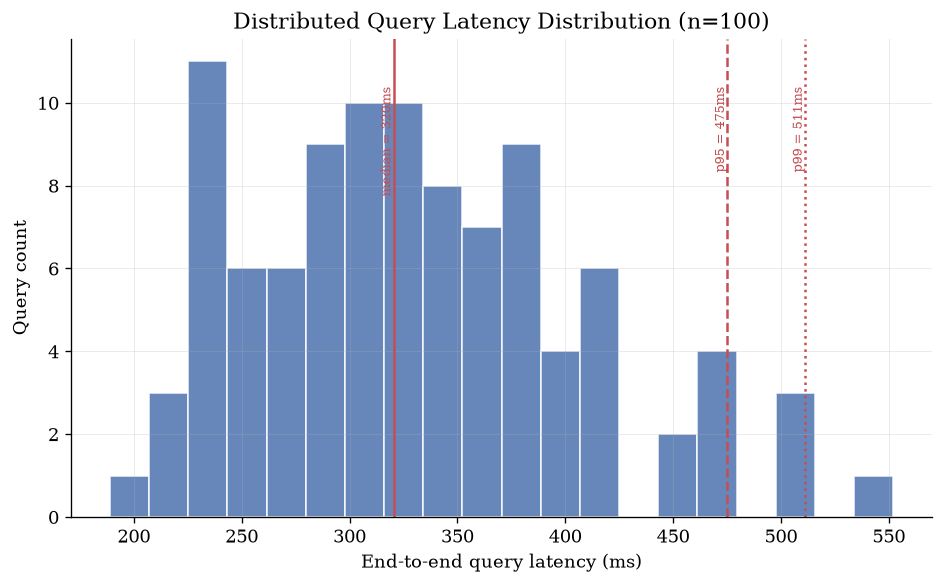

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(raw_latencies, bins=20, color="#4C72B0", alpha=0.85, edgecolor="white")
for val, label, style in [
    (lat_raw["median_ms"], f"median = {lat_raw['median_ms']:.0f}ms", "-"),
    (lat_raw["p95_ms"], f"p95 = {lat_raw['p95_ms']:.0f}ms", "--"),
    (lat_raw["p99_ms"], f"p99 = {lat_raw['p99_ms']:.0f}ms", ":"),
]:
    ax.axvline(val, color="#C44E52", linestyle=style, linewidth=1.5)
    ax.annotate(label, (val, ax.get_ylim()[1]*0.9), rotation=90, fontsize=8,
                ha="right", va="top", color="#C44E52")

ax.set_xlabel("End-to-end query latency (ms)")
ax.set_ylabel("Query count")
ax.set_title(f"Distributed Query Latency Distribution (n={lat_raw['n_queries']})")
fig.tight_layout()
save_fig(fig, "latency_breakdown")
plt.show()


## 6. Timing Breakdown (encode / shard fan-out / fuse)

**Diagnostic first:** the `encode` array's first values look like cold-start
outliers (model load / first-call JIT), not steady-state latency. The cell
below prints the raw first few values so you can visually confirm before
trusting `ENCODE_WARMUP_TRIM` in the config cell.


In [16]:
timing_raw = load_json("timing_breakdown.json")

print("First 5 'encode' values (ms):", timing_raw["encode"][:5])
print("Values 5:10                :", timing_raw["encode"][5:10])
print(f"\nUsing ENCODE_WARMUP_TRIM = {ENCODE_WARMUP_TRIM} "
      f"(set in the config cell -- change and re-run if this looks wrong).")

encode_trimmed = np.array(timing_raw["encode"][ENCODE_WARMUP_TRIM:])
shard_fanout = np.array(timing_raw["shard_fanout"])
fuse = np.array(timing_raw["fuse"])

stage_stats = pd.DataFrame([
    {"stage": "encode (warm-up trimmed)", "n": len(encode_trimmed), "mean_ms": encode_trimmed.mean(),
     "median_ms": np.median(encode_trimmed), "p95_ms": np.percentile(encode_trimmed, 95)},
    {"stage": "shard_fanout", "n": len(shard_fanout), "mean_ms": shard_fanout.mean(),
     "median_ms": np.median(shard_fanout), "p95_ms": np.percentile(shard_fanout, 95)},
    {"stage": "fuse", "n": len(fuse), "mean_ms": fuse.mean(),
     "median_ms": np.median(fuse), "p95_ms": np.percentile(fuse, 95)},
]).round(4)
stage_stats.to_csv(Path_ / "timing_breakdown_table.csv", index=False)
stage_stats.to_markdown(Path_ / "timing_breakdown_table.md", index=False)
stage_stats


First 5 'encode' values (ms): [8451.959584999713, 23413.136532999488, 275.57178599818144, 455.6527319982706, 294.2952070006868]
Values 5:10                : [251.3903190010751, 259.62245499977143, 307.7828040004533, 165.47556899968185, 251.64317300004768]

Using ENCODE_WARMUP_TRIM = 2 (set in the config cell -- change and re-run if this looks wrong).


,stage,n,mean_ms,median_ms,p95_ms
0,encode (warm-up trimmed),98,175.8991,164.3547,309.3575
1,shard_fanout,100,7.5707,6.7056,9.7228
2,fuse,100,0.0075,0.0068,0.0104


Saved timing_breakdown_stages.png / timing_breakdown_stages.pdf -> results/figures_final/


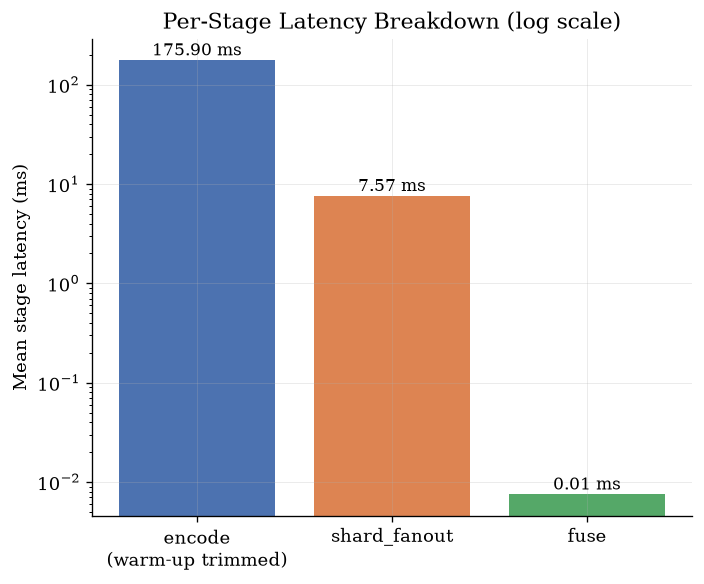


Note: y-axis is log-scaled because 'encode' dominates by roughly two orders of magnitude over 'shard_fanout' and 'fuse' -- a linear axis would make the latter two invisible.


In [17]:
fig, ax = plt.subplots(figsize=(6, 5))
stages = ["encode\n(warm-up trimmed)", "shard_fanout", "fuse"]
means = [encode_trimmed.mean(), shard_fanout.mean(), fuse.mean()]
colors = ["#4C72B0", "#DD8452", "#55A868"]
bars = ax.bar(stages, means, color=colors)
for b, v in zip(bars, means):
    ax.annotate(f"{v:.2f} ms", (b.get_x() + b.get_width()/2, v), textcoords="offset points",
                xytext=(0, 3), ha="center", fontsize=10)
ax.set_ylabel("Mean stage latency (ms)")
ax.set_yscale("log")
ax.set_title("Per-Stage Latency Breakdown (log scale)")
fig.tight_layout()
save_fig(fig, "timing_breakdown_stages")
plt.show()

print("\nNote: y-axis is log-scaled because 'encode' dominates by roughly two "
      "orders of magnitude over 'shard_fanout' and 'fuse' -- a linear axis would "
      "make the latter two invisible.")


## 7. Summary

All figures saved to `results/figures_final/` (both `.png` and vector `.pdf`).
All formatted tables saved to `tables_formatted/` (both `.csv` and `.md`).

**Before pasting into the manuscript, double check:**
- The epoch-3 completeness warning printed in section 1 (if any) — confirm whether epoch 3 is meant to only have an `oracle` row (native v3, no compensation needed) or whether this is a real data gap.
- The `ENCODE_WARMUP_TRIM` diagnostic in section 6 — confirm the trim count matches what actually happened during benchmarking (was there an explicit warm-up phase in the benchmarking script?).
